<a href="https://colab.research.google.com/github/hidrofluorik/Dataset-Google-Play-Store-Apps/blob/main/Tugas_Kelompok_K-Means_PlayStore4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

# Load the googleplaystore dataset
df = pd.read_csv('/content/googleplaystore.csv')
print("Dataset loaded successfully with shape:", df.shape)

Dataset loaded successfully with shape: (10841, 13)


In [ ]:
print("=== Jumlah Nilai Kosong per Kolom ===")
print(df.isnull().sum())
print("\nTotal Nilai Kosong Keseluruhan:", df.isnull().sum().sum())
print("\n=== Jumlah Baris Duplikat ===")
print("Total Baris Duplikat:", df.duplicated().sum())

=== Jumlah Nilai Kosong per Kolom ===
App                  0
Category             0
Rating            1474
Reviews              0
Size                 0
Installs             0
Type                 1
Price                0
Content Rating       1
Genres               0
Last Updated         0
Current Ver          8
Android Ver          3
dtype: int64

Total Nilai Kosong Keseluruhan: 1487

=== Jumlah Baris Duplikat ===
Total Baris Duplikat: 483


# Pembersihan Dataset (Data Cleaning)

Sebelum melakukan proses clustering, dilakukan pembersihan data untuk memastikan dataset memiliki kualitas dan konsistensi yang baik. Tahapan pembersihan data meliputi:

1. **Menghapus data duplikat**, yaitu baris yang memiliki seluruh nilai identik agar tidak terjadi penghitungan data yang berulang.
2. **Menghapus nilai kosong pada kolom Rating**, karena Rating merupakan salah satu fitur utama dalam penelitian sehingga aplikasi tanpa nilai rating tidak dapat digunakan untuk analisis kualitas berdasarkan fitur tersebut.
3. **Menghapus nilai Rating yang tidak valid**, yaitu nilai di luar rentang 1–5, seperti Rating sebesar 19.
4. **Menangani nilai kosong pada kolom lainnya**, seperti Type, Content Rating, Current Ver, dan Android Ver, agar informasi dataset tetap konsisten.

Setelah proses pembersihan, dataset dilanjutkan ke tahap persiapan fitur yang digunakan dalam clustering, yaitu Rating, Reviews, dan Installs.

In [ ]:

import pandas as pd

# Membaca dataset
df = pd.read_csv('/content/googleplaystore.csv')

# Membersihkan nama kolom
df.columns = df.columns.str.strip()

# Mengubah Rating menjadi numerik
df['Rating'] = pd.to_numeric(df['Rating'], errors='coerce')

# 1. Menghapus baris duplikat identik
df_clean = df.drop_duplicates().copy()

# 2. Menghapus Rating kosong
df_clean = df_clean.dropna(subset=['Rating'])

# 3. Menghapus Rating yang tidak valid (di luar 1-5)
df_clean = df_clean[
    df_clean['Rating'].between(1, 5)
].copy()

# 4. Menghapus baris kosong pada kolom tertentu
columns_to_check = [
    col for col in
    ['Type', 'Content Rating', 'Current Ver', 'Android Ver']
    if col in df_clean.columns
]

df_clean = df_clean.dropna(subset=columns_to_check)

# Menampilkan hasil pembersihan
print("=== Setelah Pembersihan ===")
print("Ukuran dataset:", df_clean.shape)
print("\nJumlah nilai kosong:")
print(df_clean.isnull().sum())
print("\nJumlah duplikat:", df_clean.duplicated().sum())


=== Setelah Pembersihan ===
Ukuran dataset: (8886, 13)

Jumlah nilai kosong:
App               0
Category          0
Rating            0
Reviews           0
Size              0
Installs          0
Type              0
Price             0
Content Rating    0
Genres            0
Last Updated      0
Current Ver       0
Android Ver       0
dtype: int64

Jumlah duplikat: 0


### Menghitung Korelasi antara Rating dan Reviews

Sebelum menghitung korelasi, kita perlu memastikan tipe data kedua kolom tersebut adalah numerik.

In [ ]:

import pandas as pd
import numpy as np

# Mengambil data hasil cleaning
df_kmeans = df_clean.copy()

# Mengubah fitur menjadi numerik
df_kmeans['Rating'] = pd.to_numeric(
    df_kmeans['Rating'], errors='coerce'
)

df_kmeans['Reviews'] = pd.to_numeric(
    df_kmeans['Reviews'], errors='coerce'
)

# Membersihkan format Installs
df_kmeans['Installs'] = (
    df_kmeans['Installs'].astype(str)
    .str.replace(',', '', regex=False)
    .str.replace('+', '', regex=False)
)

df_kmeans['Installs'] = pd.to_numeric(
    df_kmeans['Installs'], errors='coerce'
)

# Mengambil tiga fitur utama
fitur = ['Rating', 'Reviews', 'Installs']
df_kmeans = df_kmeans[fitur].copy()

# Menghapus data kosong dan nilai tidak valid
df_kmeans = df_kmeans.dropna()

df_kmeans = df_kmeans[
    (df_kmeans['Rating'].between(1, 5)) &
    (df_kmeans['Reviews'] >= 0) &
    (df_kmeans['Installs'] >= 0)
].copy()

print("Jumlah data setelah preprocessing:",
      df_kmeans.shape[0])

print("\nStatistik deskriptif:")
display(df_kmeans.describe())

# Transformasi logaritma pada Reviews dan Installs
df_kmeans_transform = df_kmeans.copy()

df_kmeans_transform['Reviews'] = np.log1p(
    df_kmeans_transform['Reviews']
)

df_kmeans_transform['Installs'] = np.log1p(
    df_kmeans_transform['Installs']
)

print("\nData setelah transformasi log1p:")
display(df_kmeans_transform.head())


Jumlah data setelah preprocessing: 8886

Statistik deskriptif:


,Rating,Reviews,Installs
count,8886.000000,8.886000e+03,8.886000e+03
mean,4.187959,4.730928e+05,1.650061e+07
std,0.522428,2.906007e+06,8.640413e+07
min,1.000000,1.000000e+00,1.000000e+00
25%,4.000000,1.640000e+02,1.000000e+04
50%,4.300000,4.723000e+03,5.000000e+05
75%,4.500000,7.131325e+04,5.000000e+06
max,5.000000,7.815831e+07,1.000000e+09



Data setelah transformasi log1p:


,Rating,Reviews,Installs
0,4.1,5.075174,9.210440
1,3.9,6.875232,13.122365
2,4.7,11.379520,15.424949
3,4.5,12.281389,17.727534
4,4.3,6.875232,11.512935


### Penanganan Nilai Ekstrem pada Reviews dan Installs

Fitur Reviews dan Installs memiliki rentang nilai yang sangat besar dan distribusi yang cenderung menceng ke kanan (*right-skewed*). Hal ini disebabkan oleh adanya aplikasi dengan jumlah ulasan dan pemasangan yang jauh lebih tinggi dibandingkan aplikasi lainnya.

Nilai ekstrem pada kedua fitur tersebut tidak langsung dihapus karena dapat merepresentasikan aplikasi yang memang memiliki popularitas tinggi. Menghapusnya secara langsung berisiko menghilangkan informasi penting dalam proses segmentasi aplikasi.

Oleh karena itu, dilakukan transformasi logaritma menggunakan metode `log1p` untuk mengurangi kemencengan distribusi dan memperkecil rentang nilai. Dengan demikian, pengaruh perbedaan skala pada Reviews dan Installs dapat dikurangi sebelum dilakukan standardisasi dan pemodelan K-Means.

            Rating   Reviews  Installs
Rating    1.000000  0.068724  0.050869
Reviews   0.068724  1.000000  0.633422
Installs  0.050869  0.633422  1.000000


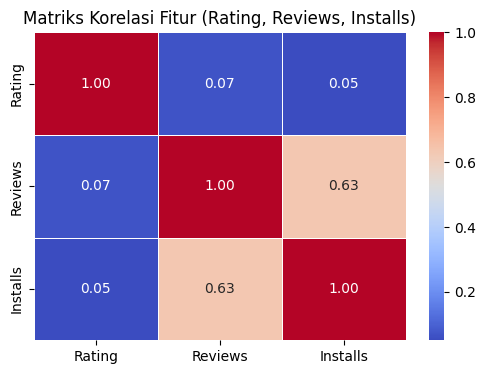

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Hitung korelasi
corr = df_kmeans[['Rating', 'Reviews', 'Installs']].corr()
print(corr)

# Heatmap korelasi
plt.figure(figsize=(6, 4))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Matriks Korelasi Fitur (Rating, Reviews, Installs)')
plt.show()

### Pemilihan Fitur untuk Proses Clustering

Pada penelitian ini, tidak seluruh fitur yang terdapat dalam dataset Google Play Store digunakan dalam proses clustering. Penelitian difokuskan pada tiga fitur utama, yaitu **Rating, Reviews, dan Installs**. Pemilihan ketiga fitur tersebut didasarkan pada relevansinya dalam menggambarkan kualitas dan tingkat penerimaan suatu aplikasi oleh pengguna.

- **Rating** digunakan untuk menggambarkan tingkat kepuasan pengguna terhadap aplikasi berdasarkan penilaian dengan skala 1–5.
- **Reviews** digunakan untuk menunjukkan jumlah ulasan yang diberikan pengguna, sehingga dapat menggambarkan tingkat keterlibatan dan respons pengguna terhadap aplikasi.
- **Installs** digunakan untuk menunjukkan jumlah pemasangan aplikasi, yang dapat menjadi indikator popularitas dan tingkat penerimaan aplikasi oleh pengguna.

Ketiga fitur tersebut dipilih karena dapat memberikan gambaran dari aspek penilaian pengguna, respons pengguna, serta popularitas aplikasi. Dengan menggabungkan ketiganya, proses clustering diharapkan dapat menghasilkan kelompok aplikasi dengan karakteristik yang berbeda sehingga dapat membantu mengidentifikasi aplikasi yang memiliki karakteristik kualitas lebih baik.

Selanjutnya, matriks korelasi digunakan untuk mengetahui hubungan antarfitur yang dipilih serta melihat tingkat keterkaitan antara Rating, Reviews, dan Installs sebelum proses clustering dilakukan.

# Eksplorasi Data Awal (Exploratory Data Analysis - EDA)
Bagian ini bertujuan untuk memvisualisasikan distribusi data asli dan melihat hubungan antar variabel sebelum algoritma K-Means diterapkan.
1. **Distribusi Fitur (Sebelum Log):** Memperlihatkan *skewness* (kemencengan) pada data `Reviews` dan `Installs`, yang menjadi alasan utama mengapa transformasi logaritmik diperlukan.
2. **Korelasi & Scatter Plot:** Menunjukkan matriks korelasi dan sebaran awal data untuk melihat potensi pengelompokan (*clustering*).

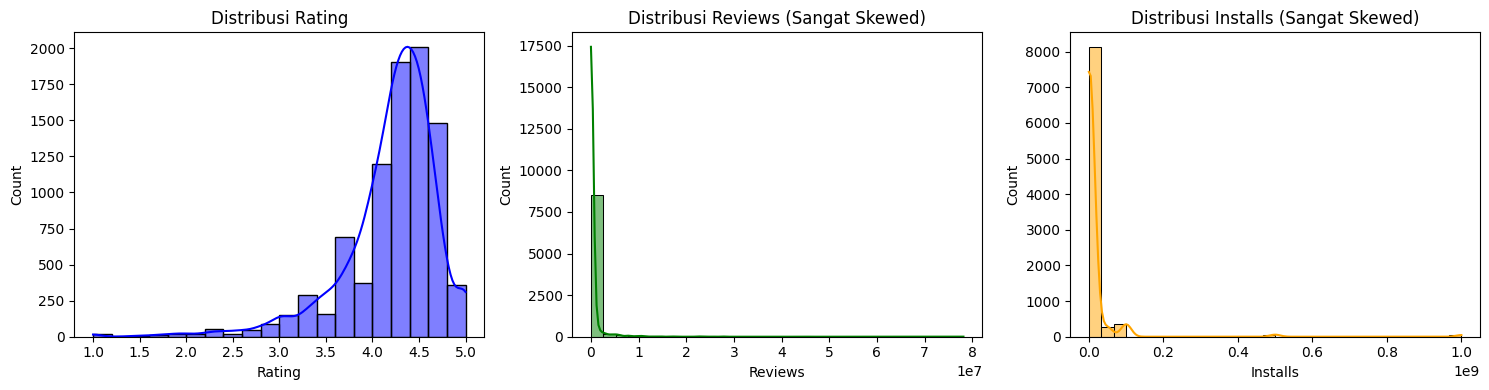

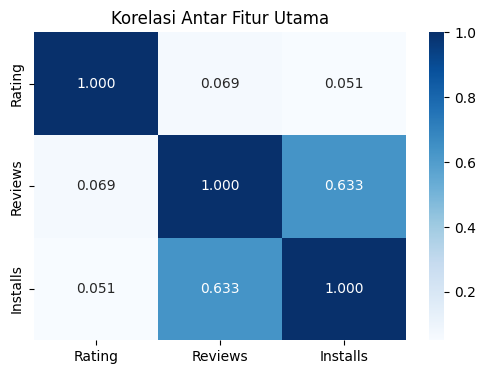

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# --- 1. Visualisasi Distribusi Fitur (Sebelum Log) ---
plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
sns.histplot(df_kmeans['Rating'], bins=20, kde=True, color='blue')
plt.title('Distribusi Rating')

plt.subplot(1, 3, 2)
sns.histplot(df_kmeans['Reviews'], bins=30, kde=True, color='green')
plt.title('Distribusi Reviews (Sangat Skewed)')

plt.subplot(1, 3, 3)
sns.histplot(df_kmeans['Installs'], bins=30, kde=True, color='orange')
plt.title('Distribusi Installs (Sangat Skewed)')

plt.tight_layout()
plt.show()

# --- 2. Matriks Korelasi (Heatmap) ---
plt.figure(figsize=(6, 4))
corr_matrix = df_kmeans[['Rating', 'Reviews', 'Installs']].corr()
sns.heatmap(corr_matrix, annot=True, cmap='Blues', fmt='.3f')
plt.title('Korelasi Antar Fitur Utama')
plt.show()

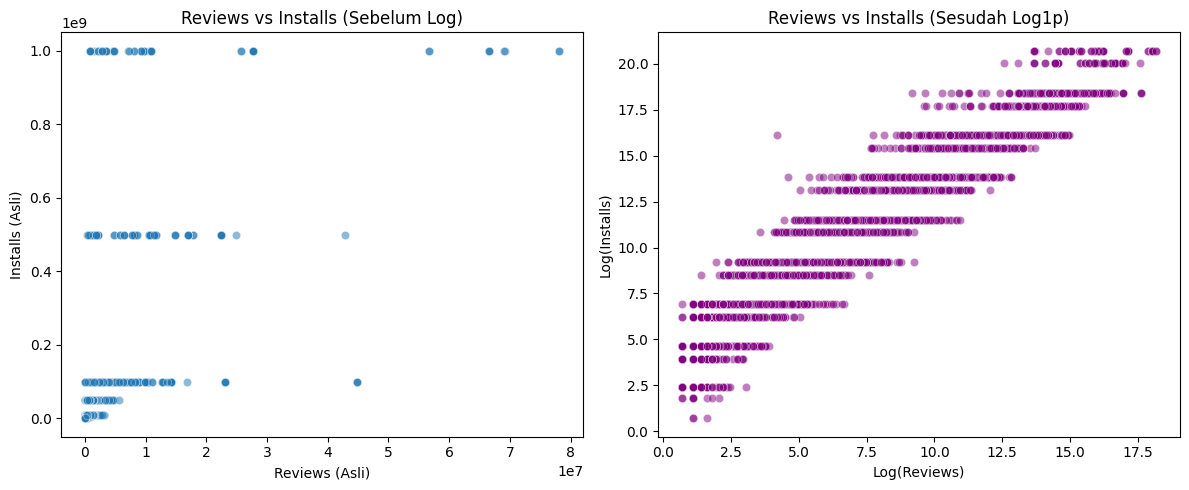

In [ ]:
# --- 3. Visualisasi Scatter Plot (Sebelum & Sesudah Log) ---
plt.figure(figsize=(12, 5))

# Scatter plot SEBELUM transformasi log (Reviews vs Installs)
plt.subplot(1, 2, 1)
sns.scatterplot(x=df_kmeans['Reviews'], y=df_kmeans['Installs'], alpha=0.5)
plt.title('Reviews vs Installs (Sebelum Log)')
plt.xlabel('Reviews (Asli)')
plt.ylabel('Installs (Asli)')

# Scatter plot SESUDAH transformasi log (Reviews vs Installs)
plt.subplot(1, 2, 2)
sns.scatterplot(x=df_kmeans_transform['Reviews'], y=df_kmeans_transform['Installs'], alpha=0.5, color='purple')
plt.title('Reviews vs Installs (Sesudah Log1p)')
plt.xlabel('Log(Reviews)')
plt.ylabel('Log(Installs)')

plt.tight_layout()
plt.show()

=== Matriks Korelasi (Pearson) ===


,Rating,Reviews,Installs
Rating,1.000000,0.068711,0.050881
Reviews,0.068711,1.000000,0.633376
Installs,0.050881,0.633376,1.000000


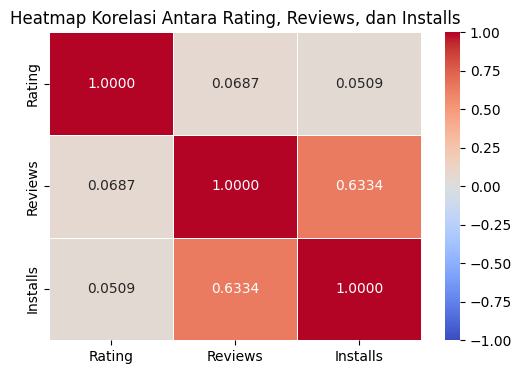

In [20]:
import seaborn as sns
import matplotlib.pyplot as plt

# Menghitung matriks korelasi antara Rating, Reviews, dan Installs
correlation_matrix = df_kmeans[['Rating', 'Reviews', 'Installs']].corr(method='pearson')

print("=== Matriks Korelasi (Pearson) ===")
display(correlation_matrix)

# Visualisasi Heatmap Korelasi
plt.figure(figsize=(6, 4))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.4f', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Heatmap Korelasi Antara Rating, Reviews, dan Installs')
plt.show()

# Standardisasi Fitur
Setelah transformasi logaritma, ketiga fitur perlu distandardisasi agar memiliki skala yang sebanding. Standardisasi dilakukan sebelum K-Means karena algoritma ini menggunakan jarak antar data.

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_kmeans_transform[fitur])

print("Ukuran data setelah standardisasi:", X_scaled.shape)
print("Rata-rata setiap fitur:", X_scaled.mean(axis=0).round(3))
print("Standar deviasi setiap fitur:", X_scaled.std(axis=0).round(3))



# Perbandingan Hasil Sebelum dan Sesudah Transformasi Log1p

Pada tahap ini dilakukan eksperimen untuk membandingkan pengaruh transformasi log1p terhadap hasil clustering K-Means. Perbandingan dilakukan menggunakan data sebelum dan sesudah transformasi logaritma pada fitur Reviews dan Installs.

Kedua kondisi menggunakan fitur yang sama, jumlah cluster yang sama, serta parameter K-Means yang sama agar pengaruh transformasi data dapat diamati secara lebih objektif.

Evaluasi dilakukan menggunakan Silhouette Score dan distribusi jumlah anggota pada setiap cluster.


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Data tanpa transformasi log
X_tanpa_log = StandardScaler().fit_transform(
    df_kmeans[fitur]
)

# Data dengan transformasi log
X_dengan_log = StandardScaler().fit_transform(
    df_kmeans_transform[fitur]
)

# Perbandingan kedua perlakuan
for nama, X in [
    ("Tanpa Log1p", X_tanpa_log),
    ("Dengan Log1p", X_dengan_log)
]:
    model = KMeans(
        n_clusters=3,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X)

    score = silhouette_score(X, labels)

    print("\nPerlakuan:", nama)
    print("Silhouette Score:", round(score, 4))
    print("Jumlah anggota cluster:")
    print(pd.Series(labels).value_counts().sort_index())


Perlakuan: Tanpa Log1p
Silhouette Score: 0.5827
Jumlah anggota cluster:
0    7199
1    1570
2     117
Name: count, dtype: int64

Perlakuan: Dengan Log1p
Silhouette Score: 0.4543
Jumlah anggota cluster:
0    1069
1    4582
2    3235
Name: count, dtype: int64



# Interpretasi Hasil Perbandingan Transformasi Log1p

Berdasarkan hasil eksperimen, diperoleh nilai Silhouette Score sebesar 0,5827 pada data tanpa transformasi log1p dan 0,4543 pada data dengan transformasi log1p.

Hasil tersebut menunjukkan bahwa data tanpa transformasi log1p menghasilkan nilai Silhouette Score yang lebih tinggi. Hal ini mengindikasikan bahwa pemisahan antar-cluster pada data tanpa transformasi lebih baik berdasarkan metrik Silhouette Score.

Namun, berdasarkan distribusi jumlah anggota cluster, data tanpa transformasi menghasilkan kelompok yang kurang merata, yaitu 7.199 data pada cluster 0, 1.570 data pada cluster 1, dan 117 data pada cluster 2.

Sementara itu, setelah dilakukan transformasi log1p, distribusi anggota cluster menjadi lebih merata, yaitu 1.069 data pada cluster 0, 4.582 data pada cluster 1, dan 3.235 data pada cluster 2.

Dengan demikian, transformasi log1p memberikan pengaruh terhadap hasil pengelompokan aplikasi. Transformasi ini membantu mengurangi dominasi nilai Reviews dan Installs yang sangat besar sehingga menghasilkan distribusi cluster yang lebih seimbang. Meskipun demikian, nilai Silhouette Score mengalami penurunan setelah transformasi.

Berdasarkan hasil tersebut, transformasi log1p memiliki kelebihan dalam menghasilkan distribusi cluster yang lebih merata, sedangkan data tanpa transformasi menghasilkan kualitas pemisahan cluster yang lebih tinggi berdasarkan Silhouette Score. Pemilihan perlakuan data perlu mempertimbangkan tujuan segmentasi yang ingin dicapai.


# Menentukan Jumlah Cluster dengan Elbow Method
Elbow Method dijalankan untuk nilai K dari 2 sampai 10. Nilai inertia (Within-Cluster Sum of Squares) dicatat pada setiap K. Semakin kecil inertia, semakin dekat data di dalam cluster. Namun, inertia akan terus menurun ketika jumlah cluster bertambah, sehingga jumlah K dipilih dari titik ketika penurunan inertia mulai melandai.

In [ ]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

k_values = range(2, 11)
inertia_values = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(X_scaled)
    inertia_values.append(kmeans.inertia_)

# Tabel nilai inertia untuk setiap K
elbow_results = pd.DataFrame({
    'Jumlah Cluster (K)': list(k_values),
    'Inertia': inertia_values
})

display(elbow_results)


,Jumlah Cluster (K),Inertia
0,2,13884.808143
1,3,9409.859031
2,4,7062.291463
3,5,5925.165981
4,6,4998.130911
5,7,4244.245271
6,8,3830.409821
7,9,3447.174368
8,10,3104.508323


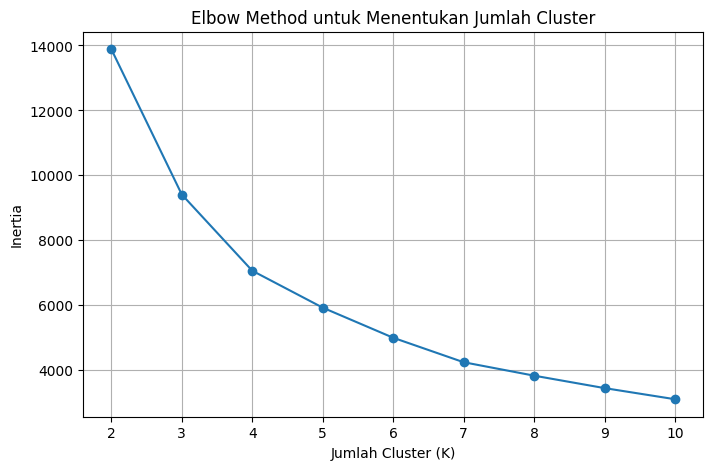

In [ ]:
# Visualisasi Elbow Method
plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertia_values, marker='o')
plt.title('Elbow Method untuk Menentukan Jumlah Cluster')
plt.xlabel('Jumlah Cluster (K)')
plt.ylabel('Inertia')
plt.xticks(list(k_values))
plt.grid(True)
plt.show()


# Analisis Hasil Elbow Method
Amati grafik dan cari titik yang membentuk siku (elbow), yaitu saat penurunan inertia yang awalnya tajam mulai melandai. Titik tersebut menjadi kandidat jumlah cluster yang efisien.

# Kesimpulan Sementara
Berdasarkan grafik Elbow Method, kita dapat menentukan jumlah cluster (K) yang paling sesuai dari titik siku pada grafik. Hasil ini nantinya akan dibandingkan dengan Silhouette Score untuk mendapatkan jumlah cluster yang tepat. Setelah itu, setiap cluster akan dilihat karakteristiknya untuk mengetahui kelompok aplikasi yang berkualitas.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [ ]:
hasil_silhouette = []

for k in range(2, 11):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    # Membentuk cluster
    labels = model.fit_predict(X_scaled)

    # Menghitung Silhouette Score seluruh data
    skor = silhouette_score(
        X_scaled,
        labels
    )

    hasil_silhouette.append({
        'K': k,
        'Silhouette Score': skor
    })

df_silhouette = pd.DataFrame(hasil_silhouette)

display(df_silhouette)

,K,Silhouette Score
0,2,0.441136
1,3,0.454341
2,4,0.371099
3,5,0.357439
4,6,0.360234
5,7,0.343803
6,8,0.331569
7,9,0.322939
8,10,0.331920


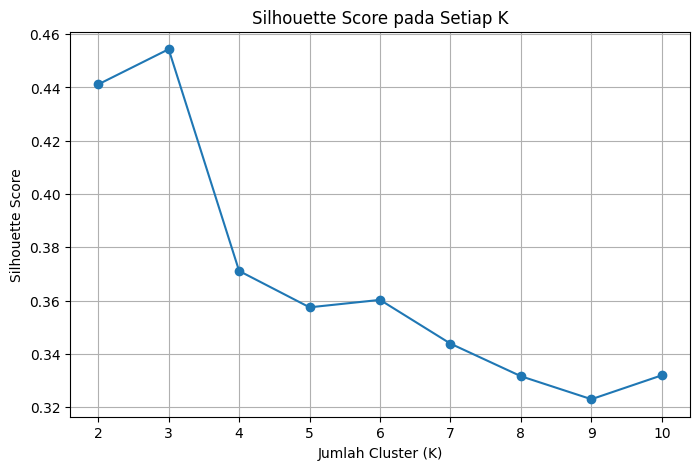

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    df_silhouette['K'],
    df_silhouette['Silhouette Score'],
    marker='o'
)

plt.title('Silhouette Score pada Setiap K')
plt.xlabel('Jumlah Cluster (K)')
plt.ylabel('Silhouette Score')

plt.xticks(range(2, 11))
plt.grid(True)

plt.show()

# **Interpretasi Hasil Silhouette Score**

Berdasarkan hasil pengujian Silhouette Score pada jumlah cluster K=2 hingga K=10, diperoleh nilai tertinggi pada K=3 sebesar 0.454341. Hal ini menunjukkan bahwa penggunaan 3 cluster menghasilkan kualitas pemisahan kelompok yang paling baik dibandingkan jumlah cluster lainnya yang diuji.

Nilai Silhouette Score yang positif dan mendekati 0,5 menunjukkan bahwa struktur pengelompokan sudah terbentuk, meskipun masih terdapat kemungkinan tumpang tindih antar-cluster.

Dengan demikian, berdasarkan evaluasi Silhouette Score, jumlah cluster K=3 menjadi kandidat terbaik untuk proses segmentasi aplikasi Google Play Store.

Berdasarkan hasil Elbow Method, penurunan nilai inertia terlihat cukup tajam dari K=2 hingga K=3, kemudian penurunannya mulai melandai pada jumlah cluster berikutnya. Hal ini menunjukkan bahwa jumlah cluster yang sesuai berada di sekitar K=3 hingga K=4.

Selanjutnya, hasil evaluasi menggunakan Silhouette Score menunjukkan bahwa K=3 memperoleh nilai tertinggi dibandingkan jumlah cluster lainnya. Hasil tersebut menunjukkan bahwa penggunaan 3 cluster memberikan kualitas pemisahan kelompok yang paling baik berdasarkan pengujian Silhouette Score.

Dengan mempertimbangkan kedua metode tersebut, dipilih jumlah cluster sebanyak 3 (K=3) untuk proses clustering aplikasi Google Play Store. Pemilihan ini didasarkan pada perubahan penurunan inertia pada Elbow Method serta nilai Silhouette Score tertinggi pada K=3.

### Penerapan K-Means dengan K=3 dan Analisis Karakteristik Cluster

Setelah menentukan jumlah cluster optimal (K=3), kita akan menjalankan algoritma K-Means pada data yang telah distandardisasi (`X_scaled`). Hasil label cluster kemudian dimasukkan kembali ke data asli sebelum transformasi (`df_kmeans`) agar kita dapat menginterpretasikan karakteristik setiap cluster menggunakan nilai aslinya (Rating, Reviews, dan Installs).

In [1]:
from sklearn.cluster import KMeans

# Memodelkan K-Means dengan K=3
kmeans_final = KMeans(n_clusters=3, random_state=42, n_init=10)
cluster_labels = kmeans_final.fit_predict(X_scaled)

# Memasukkan label cluster ke DataFrame asli dan ter-transformasi
df_kmeans['Cluster'] = cluster_labels
df_kmeans_transform['Cluster'] = cluster_labels

# Menampilkan jumlah anggota per cluster
print("=== Jumlah Anggota per Cluster ===")
print(df_kmeans['Cluster'].value_counts().sort_index())


NameError: name 'X_scaled' is not defined

### Profiling Cluster

Mari kita hitung rata-rata (*mean*) dan nilai median dari fitur utama (`Rating`, `Reviews`, `Installs`) untuk setiap cluster guna memahami karakteristik unik masing-masing kelompok.

In [2]:
# Menghitung rata-rata nilai asli per cluster
cluster_profile = df_kmeans.groupby('Cluster')[['Rating', 'Reviews', 'Installs']].agg(['mean', 'median', 'count'])
display(cluster_profile)


NameError: name 'df_kmeans' is not defined

### Penanganan NameError & Eksperimen Perbandingan Fitur

Untuk menghindari masalah `NameError`, kita akan mendefinisikan kembali variabel `df_kmeans` dan `X_scaled` dengan menjalankan proses penyiapan data dari awal di sel ini. Setelah itu, kita akan membandingkan Set Fitur Lengkap (Rating, Reviews, Installs) melawan Set Fitur Baru (Rating, Installs, Size) untuk melihat kombinasi mana yang menghasilkan struktur klastering terbaik.

In [16]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Membaca dataset yang tersedia
filepath = '/content/googleplaystore_rating_review_installs_price_size (1).csv'
df_main = pd.read_csv(filepath, encoding='latin-1')
df_main.columns = df_main.columns.str.strip()

# Pembersihan awal
df_main['Rating'] = pd.to_numeric(df_main['Rating'], errors='coerce')
df_clean = df_main.drop_duplicates(subset=['App']).copy()
df_clean = df_clean.dropna(subset=['Rating'])
df_clean = df_clean[df_clean['Rating'].between(1, 5)].copy()

# 1. Penyiapan Data Set A
df_A = df_clean.copy()
df_A['Reviews'] = pd.to_numeric(df_A['Reviews'], errors='coerce')
df_A['Installs'] = pd.to_numeric(df_A['Installs'].astype(str).str.replace(',', '').str.replace('+', ''), errors='coerce')
df_A = df_A[['App', 'Rating', 'Reviews', 'Installs']].dropna()

# Transformasi log Set A
df_A_transform = df_A.copy()
df_A_transform['Reviews'] = np.log1p(df_A_transform['Reviews'])
df_A_transform['Installs'] = np.log1p(df_A_transform['Installs'])

scaler_A = StandardScaler()
X_scaled_A = scaler_A.fit_transform(df_A_transform[['Rating', 'Reviews', 'Installs']])

kmeans_A = KMeans(n_clusters=3, random_state=42, n_init=10)
labels_A = kmeans_A.fit_predict(X_scaled_A)
sil_A = silhouette_score(X_scaled_A, labels_A)

df_A['Cluster'] = labels_A

print("=== EVALUASI SILHOUETTE SCORE (K=3) ===")
print(f"Silhouette Score Set A (Rating, Reviews, Installs) : {sil_A:.4f} (Jumlah data: {df_A.shape[0]})")

# 2. Penyiapan Data Set B
if 'Size' in df_clean.columns:
    def clean_size(val):
        val = str(val).lower().strip()
        if 'varies with device' in val or 'nan' in val or val == '':
            return np.nan
        if 'm' in val:
            return float(val.replace('m', ''))
        if 'k' in val:
            return float(val.replace('k', '')) / 1024.0
        try:
            return float(val)
        except:
            return np.nan

    df_B = df_clean.copy()
    df_B['Installs'] = pd.to_numeric(df_B['Installs'].astype(str).str.replace(',', '').str.replace('+', ''), errors='coerce')
    df_B['Size'] = df_B['Size'].apply(clean_size)
    df_B = df_B[['App', 'Rating', 'Installs', 'Size']].dropna()

    df_B_transform = df_B.copy()
    df_B_transform['Installs'] = np.log1p(df_B_transform['Installs'])
    df_B_transform['Size'] = np.log1p(df_B_transform['Size'])

    scaler_B = StandardScaler()
    X_scaled_B = scaler_B.fit_transform(df_B_transform[['Rating', 'Installs', 'Size']])

    kmeans_B = KMeans(n_clusters=3, random_state=42, n_init=10)
    labels_B = kmeans_B.fit_predict(X_scaled_B)
    sil_B = silhouette_score(X_scaled_B, labels_B)

    df_B['Cluster'] = labels_B
    print(f"Silhouette Score Set B (Rating, Installs, Size)    : {sil_B:.4f} (Jumlah data: {df_B.shape[0]})")
else:
    df_B = pd.DataFrame()
    print("Set B tidak dapat dievaluasi karena kolom 'Size' tidak ditemukan pada file csv terpilih.")

=== EVALUASI SILHOUETTE SCORE (K=3) ===
Silhouette Score Set A (Rating, Reviews, Installs) : 0.4498 (Jumlah data: 8196)
Set B tidak dapat dievaluasi karena kolom 'Size' tidak ditemukan pada file csv terpilih.


### Profiling Perbandingan Cluster

Mari kita tampilkan karakteristik rata-rata tiap klaster untuk kedua kombinasi fitur.

In [17]:
print("=== PROFIL CLUSTER SET A (Rating, Reviews, Installs) ===")
if 'df_A' in globals() and not df_A.empty:
    profile_A = df_A.groupby('Cluster')[['Rating', 'Reviews', 'Installs']].agg(['mean', 'median', 'count'])
    display(profile_A)
else:
    print("Data Set A tidak tersedia.")

print("\n=== PROFIL CLUSTER SET B (Rating, Installs, Size) ===")
if 'df_B' in globals() and not df_B.empty:
    profile_B = df_B.groupby('Cluster')[['Rating', 'Installs', 'Size']].agg(['mean', 'median', 'count'])
    display(profile_B)
else:
    print("Data Set B tidak tersedia karena kolom 'Size' absen dari file csv terpilih.")

=== PROFIL CLUSTER SET A (Rating, Reviews, Installs) ===


Rating                     Reviews                     Installs  \
             mean median count           mean   median count          mean   
Cluster                                                                      
0        4.396995    4.4  2928     445.329918    114.0  2928  2.706128e+04   
1        4.286044    4.3  4156  502751.993985  42421.0  4156  1.800907e+07   
2        3.162500    3.3  1112    1168.921763    155.0  1112  1.727877e+05   

                          
            median count  
Cluster                   
0          10000.0  2928  
1        1000000.0  4156  
2          10000.0  1112


=== PROFIL CLUSTER SET B (Rating, Installs, Size) ===
Data Set B tidak tersedia karena kolom 'Size' absen dari file csv terpilih.


/tmp/ipykernel_2865/2550689540.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Cluster', y='Rating', data=df_A, palette='Set2')


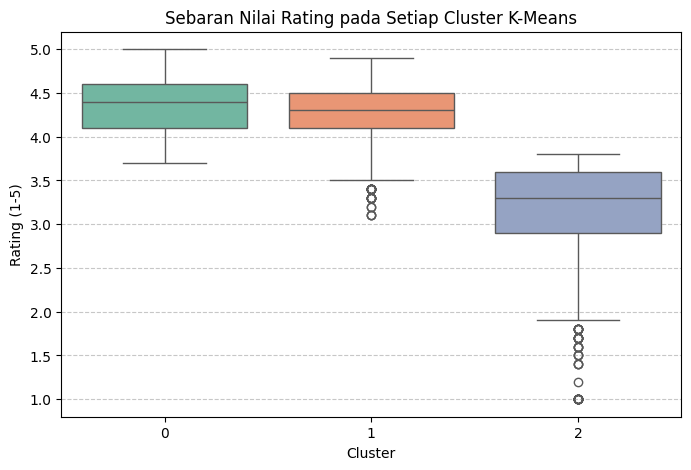

=== Statistik Deskriptif Fitur Rating per Cluster ===


,count,mean,median,min,max,std
Cluster,,,,,,
0,2928,4.396995,4.4,3.7,5.0,0.335902
1,4156,4.286044,4.3,3.1,4.9,0.285186
2,1112,3.162500,3.3,1.0,3.8,0.566231


In [22]:
import seaborn as sns
import matplotlib.pyplot as plt

# Memastikan df_A memiliki label klaster
if 'df_A' in globals() and 'Cluster' in df_A.columns:
    # 1. Visualisasi Boxplot Sebaran Rating per Cluster
    plt.figure(figsize=(8, 5))
    sns.boxplot(x='Cluster', y='Rating', data=df_A, palette='Set2')
    plt.title('Sebaran Nilai Rating pada Setiap Cluster K-Means')
    plt.xlabel('Cluster')
    plt.ylabel('Rating (1-5)')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.show()

    # 2. Statistik Deskriptif Rating per Cluster
    rating_desc = df_A.groupby('Cluster')['Rating'].agg(['count', 'mean', 'median', 'min', 'max', 'std'])
    print("=== Statistik Deskriptif Fitur Rating per Cluster ===")
    display(rating_desc)
else:
    print("Data df_A atau kolom 'Cluster' belum tersedia di kernel.")

### Analisis Korelasi antara Klaster K-Means dan Fitur Rating

Berdasarkan visualisasi dan statistik deskriptif di atas, kita dapat melihat korelasi yang sangat jelas antara segmentasi klaster dengan fitur **Rating**:

1. **Cluster 2: Kelompok Aplikasi "Perlu Perbaikan" (Rating Rendah)**
   * Memiliki rata-rata rating terendah (**3.16**) dengan nilai minimum mencapai **1.0**.
   * Klaster ini secara khusus menyaring aplikasi-aplikasi yang mendapat respon kurang memuaskan dari pengguna di Google Play Store.

2. **Cluster 0 & Cluster 1: Kelompok Aplikasi Berkualitas (Rating Tinggi)**
   * **Cluster 0** (Aplikasi Berkualitas Potensial) memiliki rata-rata rating tertinggi (**4.39**, median **4.4**).
   * **Cluster 1** (Aplikasi Populer & Sukses) juga memiliki rating yang sangat stabil di angka memuaskan (rata-rata **4.28**, median **4.3**).
   * Perbedaan utama antara Cluster 0 dan 1 bukan terletak pada kualitas (Rating), melainkan pada tingkat popularitasnya (`Installs` dan `Reviews`). Hal ini membuktikan bahwa algoritma K-Means mampu memisahkan aplikasi berkualitas tinggi yang sudah populer berskala besar dengan aplikasi berkualitas tinggi yang pasarnya masih berkembang (*niche*).

## Eksperimen Perbandingan Kombinasi Fitur K-Means

Sesuai permintaan, kita akan membandingkan efektivitas pengelompokan menggunakan dua set fitur berbeda:
- **Set A (Himpunan Fitur Lengkap):** `Rating`, `Reviews`, `Installs`
- **Set B (Kombinasi Kualitas & Popularitas + Size):** `Rating`, `Installs`, `Size` (tanpa `Reviews`)

Langkah pertama adalah melakukan preprocessing lengkap termasuk konversi fitur `Size` ke dalam format numerik (dalam MB).

In [13]:
import pandas as pd

# Membaca dataset dengan encoding 'latin-1'
df = pd.read_csv('/content/googleplaystore_rating_review_installs_price_size (1).csv', encoding='latin-1')

print("=== Kolom yang tersedia ===")
print(df.columns.tolist())
print("\n=== Contoh 3 baris data ===")
display(df.head(3))


=== Kolom yang tersedia ===
['App', 'Reviews', 'Installs', 'Rating']

=== Contoh 3 baris data ===


,App,Reviews,Installs,Rating
0,Photo Editor & Candy Camera & Grid & ScrapBook,159,"10,000+",4.1
1,Coloring book moana,967,"500,000+",3.9
2,"U Launcher Lite - FREE Live Cool Themes, Hide ...",87510,"5,000,000+",4.7


### Penerapan K-Means untuk Kedua Kombinasi Fitur

In [18]:
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Definisikan df_exp_log dari df_A_transform (Set A) yang telah didefinisikan sebelumnya
if 'df_A_transform' in globals():
    df_exp_log = df_A_transform.copy()
else:
    # Fallback jika belum didefinisikan
    df_exp_log = df_clean.copy()
    df_exp_log['Reviews'] = np.log1p(pd.to_numeric(df_exp_log['Reviews'], errors='coerce'))
    df_exp_log['Installs'] = np.log1p(pd.to_numeric(df_exp_log['Installs'].astype(str).str.replace(',', '').str.replace('+', ''), errors='coerce'))
    df_exp_log = df_exp_log.dropna(subset=['Rating', 'Reviews', 'Installs'])

# Definisikan kedua himpunan fitur
fitur_A = ['Rating', 'Reviews', 'Installs']

# Standardisasi Set A
scaler_A = StandardScaler()
X_scaled_A = scaler_A.fit_transform(df_exp_log[fitur_A])

# K-Means K=3 untuk Set A
kmeans_A = KMeans(n_clusters=3, random_state=42, n_init=10)
labels_A = kmeans_A.fit_predict(X_scaled_A)
sil_A = silhouette_score(X_scaled_A, labels_A)

print(f"Silhouette Score Set A (Rating, Reviews, Installs): {sil_A:.4f}")

# Memeriksa apakah kolom 'Size' tersedia untuk Set B
if 'Size' in df_exp_log.columns:
    fitur_B = ['Rating', 'Installs', 'Size']
    scaler_B = StandardScaler()
    X_scaled_B = scaler_B.fit_transform(df_exp_log[fitur_B])

    kmeans_B = KMeans(n_clusters=3, random_state=42, n_init=10)
    labels_B = kmeans_B.fit_predict(X_scaled_B)
    sil_B = silhouette_score(X_scaled_B, labels_B)
    print(f"Silhouette Score Set B (Rating, Installs, Size): {sil_B:.4f}")
else:
    print("Silhouette Score Set B tidak dapat dihitung karena kolom 'Size' absen dari berkas csv.")
    labels_B = None

Silhouette Score Set A (Rating, Reviews, Installs): 0.4498
Silhouette Score Set B tidak dapat dihitung karena kolom 'Size' absen dari berkas csv.


### Visualisasi Profiling & Karakteristik Segmen Aplikasi dari Kedua Set Fitur

In [19]:
# Menyiapkan dataframe asli untuk di-profile jika tersedia
if 'df_A' in globals() and not df_A.empty:
    df_exp = df_A.copy()
    df_exp['Cluster_A'] = labels_A

    print("=== PROFIL CLUSTER SET A (Rating, Reviews, Installs) ===")
    profile_A = df_exp.groupby('Cluster_A')[fitur_A].agg(['mean', 'median', 'count'])
    display(profile_A)
else:
    print("Data Set A tidak tersedia untuk profiling.")

print("\n=== PROFIL CLUSTER SET B (Rating, Installs, Size) ===")
if 'labels_B' in globals() and labels_B is not None:
    df_exp['Cluster_B'] = labels_B
    profile_B = df_exp.groupby('Cluster_B')[['Rating', 'Installs', 'Size']].agg(['mean', 'median', 'count'])
    display(profile_B)
else:
    print("Data Set B tidak tersedia karena kolom 'Size' absen dari file csv.")

=== PROFIL CLUSTER SET A (Rating, Reviews, Installs) ===


Rating                     Reviews                     Installs  \
               mean median count           mean   median count          mean   
Cluster_A                                                                      
0          4.396995    4.4  2928     445.329918    114.0  2928  2.706128e+04   
1          4.286044    4.3  4156  502751.993985  42421.0  4156  1.800907e+07   
2          3.162500    3.3  1112    1168.921763    155.0  1112  1.727877e+05   

                            
              median count  
Cluster_A                   
0            10000.0  2928  
1          1000000.0  4156  
2            10000.0  1112


=== PROFIL CLUSTER SET B (Rating, Installs, Size) ===
Data Set B tidak tersedia karena kolom 'Size' absen dari file csv.
